# Improved VAE for SIEM Anomaly Detection

Complete implementation with enhanced architecture and optimal threshold finding.

## Key Features:
- Train on **benign-only** data to learn normal behavior
- Deep VAE architecture with residual-style connections
- Optimal threshold selection using validation set
- Comprehensive evaluation on held-out test set

## Part 1: Imports and Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder, MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

PyTorch version: 2.7.1+cpu
CUDA available: False
Using device: cpu


## Part 2: Data Loading

In [3]:
print("=" * 70)
print("LOADING DATA FOR ANOMALY DETECTION")
print("=" * 70)

folder="/kaggle/input/"
benignFolder="benign-data/benign_final.xlsx"
DataFolder="merged-synthetic-benign/merged_dataset.xlsx"
# Load BENIGN data for training
print("\n📂 Loading BENIGN training data from benign_final.xlsx...")
df_benign = pd.read_excel(folder+benignFolder)
print(f"✅ Loaded {len(df_benign):,} benign samples")
print(f"   Columns: {df_benign.shape[1]}")

# Load MIXED data (benign + malicious) for testing
print("\n📂 Loading MIXED test data from merged_dataset.xlsx...")
df_mixed = pd.read_excel(folder+DataFolder)
print(f"✅ Loaded {len(df_mixed):,} mixed samples")
print(f"   Columns: {df_mixed.shape[1]}")

# Check malicious distribution in mixed data
if 'malicious' in df_mixed.columns:
    print("\n📊 Test Data Distribution:")
    print(f"   Benign: {(df_mixed['malicious'] == 0).sum():,} ({(df_mixed['malicious'] == 0).mean()*100:.1f}%)")
    print(f"   Malicious: {(df_mixed['malicious'] == 1).sum():,} ({(df_mixed['malicious'] == 1).mean()*100:.1f}%)")
else:
    print("\n⚠️  Warning: 'malicious' column not found in test data")

LOADING DATA FOR ANOMALY DETECTION

📂 Loading BENIGN training data from benign_final.xlsx...
✅ Loaded 90,308 benign samples
   Columns: 15

📂 Loading MIXED test data from merged_dataset.xlsx...
✅ Loaded 141,144 mixed samples
   Columns: 16

📊 Test Data Distribution:
   Benign: 90,308 (64.0%)
   Malicious: 50,836 (36.0%)


## Part 3: Feature Selection

We select ~20-40 fields that give behavioral signals including:
- Core fields (timestamp, agent info, IPs)
- Rule-based features (MITRE tactics, severity)
- Command and user features
- File integrity monitoring (syscheck) features

In [ ]:
LABEL_COL = "malicious"

BOOLEAN_COLS = [
    "has_audit",
    "has_syscheck",
    "has_sca",
    "has_network"
]

CATEGORICAL_COLS = [
    "cyber_kill_chain_tactic",
    "cyber_kill_chain_technique",
    "_source.rule.mitre.tactic",
    "_source.rule.mitre.id",
    "_source.rule.level",
    "_source.rule.groups",
    "_source.decoder.name",
    "_source.data.protocol"
]

# HIGH-CARDINALITY → DROP (critical for VAE stability)
DROP_COLS = [
    "_source.data.srcip",
    "_source.data.url"
]


## Part 4: Feature Processor

This class handles all feature engineering:
1. **Timestamps** → Unix epoch + hour_of_day + day_of_week
2. **IP fields** → is_private flag + missing indicator
3. **Categorical fields** → Top-K one-hot encoding
4. **Commands & Text** → Multi-hot encoding of top-N tokens
5. **Paths/Files** → Depth, sensitive dir flags, etc.
6. **Hashes** → Binary presence flags

In [10]:
import re
from collections import Counter
import ipaddress

class SIEMFeatureProcessor:
    """Feature processor for SIEM data that converts mixed fields to numeric vectors."""

    def __init__(self, top_k_tokens=100, top_k_categorical=50):
        self.top_k_tokens = top_k_tokens
        self.top_k_categorical = top_k_categorical
        self.token_vocab = {}
        self.categorical_encoders = {}
        self.scaler = StandardScaler()
        self.feature_names = []

    def _parse_timestamp(self, ts_series):
        """Convert timestamp to numeric features."""
        ts = pd.to_datetime(ts_series, errors='coerce')
        features = pd.DataFrame()
        features['epoch'] = ts.astype(np.int64) // 10**9
        features['hour_of_day'] = ts.dt.hour.fillna(0).astype(int)
        features['day_of_week'] = ts.dt.dayofweek.fillna(0).astype(int)
        features['is_weekend'] = (features['day_of_week'] >= 5).astype(int)
        features['is_night'] = ((features['hour_of_day'] >= 22) | (features['hour_of_day'] <= 6)).astype(int)
        features['epoch'] = (features['epoch'] - features['epoch'].min()) / (features['epoch'].max() - features['epoch'].min() + 1e-8)
        return features

    def _is_private_ip(self, ip_str):
        """Check if IP is private/internal."""
        try:
            if pd.isna(ip_str) or ip_str == '':
                return 0
            ip = ipaddress.ip_address(str(ip_str).strip())
            return 1 if ip.is_private else 0
        except:
            return 0

    def _process_ip(self, ip_series, prefix='ip'):
        """Process IP addresses to features."""
        features = pd.DataFrame()
        features[f'{prefix}_is_private'] = ip_series.apply(self._is_private_ip)
        features[f'{prefix}_is_missing'] = ip_series.isna().astype(int)
        return features

    def _extract_path_features(self, path_series):
        """Extract features from file paths."""
        features = pd.DataFrame()
        sensitive_dirs = ['/etc', '/var/log', '/home', '/root', '/bin', '/sbin', '/usr/bin', '/tmp']

        def get_path_features(path):
            if pd.isna(path) or path == '':
                return {'depth': 0, 'is_sensitive': 0, 'is_hidden': 0, 'has_extension': 0}
            path = str(path)
            depth = path.count('/')
            is_sensitive = int(any(d in path for d in sensitive_dirs))
            is_hidden = int('/.' in path or path.startswith('.'))
            has_extension = int('.' in path.split('/')[-1] if '/' in path else '.' in path)
            return {'depth': min(depth, 10), 'is_sensitive': is_sensitive,
                    'is_hidden': is_hidden, 'has_extension': has_extension}

        path_feats = path_series.apply(get_path_features).apply(pd.Series)
        features['path_depth'] = path_feats['depth']
        features['path_is_sensitive'] = path_feats['is_sensitive']
        features['path_is_hidden'] = path_feats['is_hidden']
        features['path_has_extension'] = path_feats['has_extension']
        features['path_is_missing'] = path_series.isna().astype(int)
        return features

    def _tokenize_text(self, text):
        """Tokenize text into words."""
        if pd.isna(text) or text == '':
            return []
        text = str(text).lower()
        tokens = re.split(r'[\s\[\]\(\)\{\}\|\\/,;:=<>\"\'`]+', text)
        tokens = [t.strip() for t in tokens if len(t.strip()) > 1]
        return tokens

    def _build_token_vocabulary(self, text_series, name):
        """Build vocabulary from top-K tokens."""
        all_tokens = []
        for text in text_series:
            all_tokens.extend(self._tokenize_text(text))
        token_counts = Counter(all_tokens)
        top_tokens = [t for t, _ in token_counts.most_common(self.top_k_tokens)]
        self.token_vocab[name] = {token: idx for idx, token in enumerate(top_tokens)}
        return self.token_vocab[name]

    def _text_to_multihot(self, text_series, vocab, prefix):
        """Convert text to multi-hot vector using vocabulary."""
        n_tokens = len(vocab)
        multihot = np.zeros((len(text_series), n_tokens), dtype=np.float32)
        for i, text in enumerate(text_series):
            tokens = self._tokenize_text(text)
            for token in tokens:
                if token in vocab:
                    multihot[i, vocab[token]] = 1
        columns = [f'{prefix}_tok_{i}' for i in range(n_tokens)]
        return pd.DataFrame(multihot, columns=columns, index=text_series.index)

    def _process_categorical(self, series, name, top_k=None):
        """Process categorical column with top-K encoding."""
        top_k = top_k or self.top_k_categorical
        series = series.fillna('<NA>')
        value_counts = series.value_counts()
        top_categories = value_counts.head(top_k).index.tolist()
        mapped = series.apply(lambda x: x if x in top_categories else '<OTHER>')
        dummies = pd.get_dummies(mapped, prefix=name, dtype=int)
        self.categorical_encoders[name] = top_categories
        return dummies

    def _process_hash_fields(self, df):
        """Process hash fields to binary features."""
        features = pd.DataFrame(index=df.index)
        if '_source.syscheck.md5_after' in df.columns:
            features['has_md5'] = df['_source.syscheck.md5_after'].notna().astype(int)
        else:
            features['has_md5'] = 0
        if '_source.syscheck.sha256_after' in df.columns:
            features['has_sha256'] = df['_source.syscheck.sha256_after'].notna().astype(int)
        else:
            features['has_sha256'] = 0
        return features

    def fit_transform(self, df):
        """Fit the processor and transform the dataframe to feature vectors."""
        print("🔄 Starting feature extraction...")
        all_features = []

        # 1. Timestamp features
        print("  📅 Processing timestamps...")
        if '_source.@timestamp' in df.columns:
            ts_features = self._parse_timestamp(df['_source.@timestamp'])
            all_features.append(ts_features)
            self.feature_names.extend(ts_features.columns.tolist())

        # 2. IP features
        print("  🌐 Processing IP addresses...")
        if '_source.agent.ip' in df.columns:
            ip_features = self._process_ip(df['_source.agent.ip'], 'agent_ip')
            all_features.append(ip_features)
            self.feature_names.extend(ip_features.columns.tolist())
        if '_source.data.srcip' in df.columns:
            ip_features = self._process_ip(df['_source.data.srcip'], 'src_ip')
            all_features.append(ip_features)
            self.feature_names.extend(ip_features.columns.tolist())

        # 3. Numeric features
        print("  🔢 Processing numeric features...")
        numeric_cols = ['_source.rule.level', '_source.rule.firedtimes', '_source.data.srcport']
        for col in numeric_cols:
            if col in df.columns:
                feat_name = col.split('.')[-1]
                values = pd.to_numeric(df[col], errors='coerce').fillna(0)
                all_features.append(pd.DataFrame({feat_name: values}))
                self.feature_names.append(feat_name)

        # 4. Path features
        print("  📁 Processing path features...")
        if '_source.syscheck.path' in df.columns:
            path_features = self._extract_path_features(df['_source.syscheck.path'])
            all_features.append(path_features)
            self.feature_names.extend(path_features.columns.tolist())

        # 5. Hash features
        print("  🔐 Processing hash features...")
        hash_features = self._process_hash_fields(df)
        all_features.append(hash_features)
        self.feature_names.extend(hash_features.columns.tolist())

        # 6. Categorical features
        print("  🏷️ Processing categorical features...")
        categorical_cols = {
            '_source.rule.mitre_tactics': 'mitre_tactic',
            '_source.syscheck.event': 'syscheck_event',
            '_source.data.protocol': 'protocol',
            '_source.decoder.name': 'decoder',
            '_source.location': 'location'
        }
        for col, name in categorical_cols.items():
            if col in df.columns:
                cat_features = self._process_categorical(df[col], name, top_k=20)
                all_features.append(cat_features)
                self.feature_names.extend(cat_features.columns.tolist())

        # 7. Text features
        print("  📝 Processing text features...")
        text_cols = {
            '_source.data.command': 'cmd',
            '_source.rule.description': 'desc',
        }
        for col, prefix in text_cols.items():
            if col in df.columns:
                vocab = self._build_token_vocabulary(df[col], prefix)
                if len(vocab) > 0:
                    text_features = self._text_to_multihot(df[col], vocab, prefix)
                    all_features.append(text_features)
                    self.feature_names.extend(text_features.columns.tolist())

        # 8. Syscheck changed attributes
        print("  🔄 Processing syscheck attributes...")
        if '_source.syscheck.changed_attributes' in df.columns:
            attrs = ['size', 'mtime', 'md5', 'sha1', 'sha256', 'permission', 'uid', 'gid']
            for attr in attrs:
                col_name = f'changed_{attr}'
                df_temp = df['_source.syscheck.changed_attributes'].fillna('')
                all_features.append(pd.DataFrame({col_name: df_temp.str.contains(attr, case=False).astype(int)}))
                self.feature_names.append(col_name)

        # Concatenate all features
        print("  🔗 Concatenating features...")
        feature_matrix = pd.concat(all_features, axis=1)
        feature_matrix = feature_matrix.fillna(0)

        # Scale numeric features
        print("  📏 Scaling numeric features...")
        numeric_to_scale = ['epoch', 'hour_of_day', 'day_of_week', 'level', 'firedtimes', 'srcport', 'path_depth']
        cols_to_scale = [c for c in numeric_to_scale if c in feature_matrix.columns]
        if cols_to_scale:
            feature_matrix[cols_to_scale] = self.scaler.fit_transform(feature_matrix[cols_to_scale])

        print(f"\n✅ Feature extraction complete!")
        print(f"   Final feature matrix shape: {feature_matrix.shape}")
        return feature_matrix

    def transform(self, df):
        """Transform new data using fitted processor."""
        print("🔄 Transforming new data with fitted processor...")
        all_features = []

        # 1. Timestamp
        if '_source.@timestamp' in df.columns:
            ts_features = self._parse_timestamp(df['_source.@timestamp'])
            all_features.append(ts_features)

        # 2. IP features
        if '_source.agent.ip' in df.columns:
            ip_features = self._process_ip(df['_source.agent.ip'], 'agent_ip')
            all_features.append(ip_features)
        if '_source.data.srcip' in df.columns:
            ip_features = self._process_ip(df['_source.data.srcip'], 'src_ip')
            all_features.append(ip_features)

        # 3. Numeric
        numeric_cols = ['_source.rule.level', '_source.rule.firedtimes', '_source.data.srcport']
        for col in numeric_cols:
            if col in df.columns:
                feat_name = col.split('.')[-1]
                values = pd.to_numeric(df[col], errors='coerce').fillna(0)
                all_features.append(pd.DataFrame({feat_name: values}, index=df.index))

        # 4. Path features
        if '_source.syscheck.path' in df.columns:
            path_features = self._extract_path_features(df['_source.syscheck.path'])
            all_features.append(path_features)

        # 5. Hash features
        hash_features = self._process_hash_fields(df)
        all_features.append(hash_features)

        # 6. Categorical - USE SAVED ENCODERS
        categorical_cols = {
            '_source.rule.mitre_tactics': 'mitre_tactic',
            '_source.syscheck.event': 'syscheck_event',
            '_source.data.protocol': 'protocol',
            '_source.decoder.name': 'decoder',
            '_source.location': 'location'
        }
        for col, name in categorical_cols.items():
            if col in df.columns and name in self.categorical_encoders:
                top_categories = self.categorical_encoders[name]
                series = df[col].fillna('<NA>')
                mapped = series.apply(lambda x: x if x in top_categories else '<OTHER>')
                dummies = pd.get_dummies(mapped, prefix=name, dtype=int)
                training_cols = [c for c in self.feature_names if c.startswith(f'{name}_')]
                aligned_dummies = pd.DataFrame(0, index=df.index, columns=training_cols, dtype=int)
                for col_name in dummies.columns:
                    if col_name in aligned_dummies.columns:
                        aligned_dummies[col_name] = dummies[col_name]
                all_features.append(aligned_dummies)

        # 7. Text - USE SAVED VOCABULARIES
        text_cols = {
            '_source.data.command': 'cmd',
            '_source.rule.description': 'desc',
        }
        for col, prefix in text_cols.items():
            if col in df.columns and prefix in self.token_vocab:
                vocab = self.token_vocab[prefix]
                if len(vocab) > 0:
                    training_text_cols = [c for c in self.feature_names if c.startswith(f'{prefix}_tok_')]
                    n_tokens = len(training_text_cols)
                    multihot = np.zeros((len(df), n_tokens), dtype=np.float32)
                    for i, text in enumerate(df[col]):
                        tokens = self._tokenize_text(text)
                        for token in tokens:
                            if token in vocab:
                                token_idx = vocab[token]
                                if token_idx < n_tokens:
                                    multihot[i, token_idx] = 1
                    text_features = pd.DataFrame(multihot, columns=training_text_cols, index=df.index)
                    all_features.append(text_features)

        # 8. Syscheck
        if '_source.syscheck.changed_attributes' in df.columns:
            attrs = ['size', 'mtime', 'md5', 'sha1', 'sha256', 'permission', 'uid', 'gid']
            for attr in attrs:
                col_name = f'changed_{attr}'
                df_temp = df['_source.syscheck.changed_attributes'].fillna('')
                all_features.append(pd.DataFrame({col_name: df_temp.str.contains(attr, case=False).astype(int)}, index=df.index))

        # Concatenate
        feature_matrix = pd.concat(all_features, axis=1)
        feature_matrix = feature_matrix.fillna(0)

        # Scale
        numeric_to_scale = ['epoch', 'hour_of_day', 'day_of_week', 'level', 'firedtimes', 'srcport', 'path_depth']
        cols_to_scale = [c for c in numeric_to_scale if c in feature_matrix.columns]
        if cols_to_scale and hasattr(self.scaler, 'mean_'):
            feature_matrix[cols_to_scale] = self.scaler.transform(feature_matrix[cols_to_scale])

        # Align columns
        missing_cols = set(self.feature_names) - set(feature_matrix.columns)
        if missing_cols:
            for col in missing_cols:
                feature_matrix[col] = 0
        extra_cols = set(feature_matrix.columns) - set(self.feature_names)
        if extra_cols:
            feature_matrix = feature_matrix.drop(columns=list(extra_cols))
        feature_matrix = feature_matrix[self.feature_names]

        print(f"✅ Transform complete: {feature_matrix.shape}")
        return feature_matrix

## Part 5: Process Features

In [11]:
print("\n" + "=" * 70)
print("PROCESSING FEATURES WITH CONSISTENT VOCABULARY")
print("=" * 70)

processor = SIEMFeatureProcessor(top_k_tokens=100, top_k_categorical=30)

print("\n📂 Step 1: FIT processor on BENIGN training data...")
X_benign_features = processor.fit_transform(df_benign)
print(f"✅ Benign features: {X_benign_features.shape}")

if 'malicious' in df_benign.columns and 'cyber_kill_chain_tactic' in df_benign.columns:
    labels_benign = df_benign[['malicious', 'cyber_kill_chain_tactic']].copy()
    labels_benign['cyber_kill_chain_tactic'] = labels_benign['cyber_kill_chain_tactic'].fillna('Unknown')
else:
    labels_benign = pd.DataFrame({
        'malicious': [0] * len(df_benign),
        'cyber_kill_chain_tactic': ['Unknown'] * len(df_benign)
    })

print("\n📂 Step 2: TRANSFORM test data using fitted processor...")
X_mixed_features = processor.transform(df_mixed)
print(f"✅ Mixed features: {X_mixed_features.shape}")

if 'malicious' in df_mixed.columns and 'cyber_kill_chain_tactic' in df_mixed.columns:
    labels_mixed = df_mixed[['malicious', 'cyber_kill_chain_tactic']].copy()
    labels_mixed['cyber_kill_chain_tactic'] = labels_mixed['cyber_kill_chain_tactic'].fillna('Unknown')
else:
    labels_mixed = pd.DataFrame({
        'malicious': [0] * len(df_mixed),
        'cyber_kill_chain_tactic': ['Unknown'] * len(df_mixed)
    })

print(f"\n✅ Verification:")
print(f"   Benign features: {X_benign_features.shape[1]}")
print(f"   Test features: {X_mixed_features.shape[1]}")
print(f"   Match: {X_benign_features.shape[1] == X_mixed_features.shape[1]}")


PROCESSING FEATURES WITH CONSISTENT VOCABULARY

📂 Step 1: FIT processor on BENIGN training data...
🔄 Starting feature extraction...
  📅 Processing timestamps...
  🌐 Processing IP addresses...
  🔢 Processing numeric features...
  📁 Processing path features...
  🔐 Processing hash features...
  🏷️ Processing categorical features...
  📝 Processing text features...
  🔄 Processing syscheck attributes...
  🔗 Concatenating features...
  📏 Scaling numeric features...

✅ Feature extraction complete!
   Final feature matrix shape: (90308, 44)
✅ Benign features: (90308, 44)

📂 Step 2: TRANSFORM test data using fitted processor...
🔄 Transforming new data with fitted processor...
✅ Transform complete: (141144, 44)
✅ Mixed features: (141144, 44)

✅ Verification:
   Benign features: 44
   Test features: 44
   Match: True


## Part 6: Prepare Data for VAE

In [12]:
X_benign = X_benign_features.values.astype(np.float32)
y_benign = labels_benign['malicious'].values

X_test = X_mixed_features.values.astype(np.float32)
y_test = labels_mixed['malicious'].values
y_ckc_test = labels_mixed['cyber_kill_chain_tactic'].values

print("\n" + "=" * 70)
print("DATA PREPARATION COMPLETE")
print("=" * 70)

print(f"\n📊 Training Data (BENIGN ONLY):")
print(f"   Shape: {X_benign.shape}")
print(f"   Benign: {np.sum(y_benign == 0):,} (100%)")

print(f"\n📊 Test Data (MIXED):")
print(f"   Shape: {X_test.shape}")
print(f"   Benign: {np.sum(y_test == 0):,} ({np.sum(y_test == 0)/len(y_test)*100:.1f}%)")
print(f"   Malicious: {np.sum(y_test == 1):,} ({np.sum(y_test == 1)/len(y_test)*100:.1f}%)")

# Split benign data into train/validation
X_train_benign, X_val_benign = train_test_split(
    X_benign, test_size=0.2, random_state=42
)

# Split mixed test data into validation/test sets for threshold tuning
X_val_mixed, X_test_final, y_val_mixed, y_test_final, y_ckc_val, y_ckc_test_final = train_test_split(
    X_test, y_test, y_ckc_test, test_size=0.5, random_state=42, stratify=y_test
)

print(f"\n📊 Benign Data Split:")
print(f"   Training: {X_train_benign.shape[0]:,} samples")
print(f"   Validation: {X_val_benign.shape[0]:,} samples")

print(f"\n📊 Mixed Data Split (for threshold tuning & final evaluation):")
print(f"   Validation: {X_val_mixed.shape[0]:,} samples (Benign: {np.sum(y_val_mixed == 0):,}, Malicious: {np.sum(y_val_mixed == 1):,})")
print(f"   Test: {X_test_final.shape[0]:,} samples (Benign: {np.sum(y_test_final == 0):,}, Malicious: {np.sum(y_test_final == 1):,})")


DATA PREPARATION COMPLETE

📊 Training Data (BENIGN ONLY):
   Shape: (90308, 44)
   Benign: 90,308 (100%)

📊 Test Data (MIXED):
   Shape: (141144, 44)
   Benign: 90,308 (64.0%)
   Malicious: 50,836 (36.0%)

📊 Benign Data Split:
   Training: 72,246 samples
   Validation: 18,062 samples

📊 Mixed Data Split (for threshold tuning & final evaluation):
   Validation: 70,572 samples (Benign: 45,154, Malicious: 25,418)
   Test: 70,572 samples (Benign: 45,154, Malicious: 25,418)


## Part 7: Improved VAE Model

### Architecture (SIEMVAE)

**Encoder:** Input → 512 → 256 → 128 → Latent (32)

**Decoder:** Latent (32) → 128 → 256 → 512 → Input

Key design choices:
- Smaller latent space (32) for stronger compression
- Batch Normalization for training stability
- Dropout (0.3) for regularization
- Xavier initialization for improved gradient flow

In [13]:
class SIEMVAE(nn.Module):
    """
    Enhanced Variational Autoencoder for SIEM anomaly detection.
    
    Key improvements:
    - Deeper encoder/decoder with residual connections
    - Better latent space dimensionality
    - Improved weight initialization
    """
    
    def __init__(self, input_dim, latent_dim=32, dropout_rate=0.3):
        super(SIEMVAE, self).__init__()
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        
        # Encoder with residual-style architecture
        self.encoder_l1 = nn.Linear(input_dim, 512)
        self.encoder_bn1 = nn.BatchNorm1d(512)
        
        self.encoder_l2 = nn.Linear(512, 256)
        self.encoder_bn2 = nn.BatchNorm1d(256)
        
        self.encoder_l3 = nn.Linear(256, 128)
        self.encoder_bn3 = nn.BatchNorm1d(128)
        
        self.dropout = nn.Dropout(dropout_rate)
        
        # Latent space
        self.fc_z_mean = nn.Linear(128, latent_dim)
        self.fc_z_log_var = nn.Linear(128, latent_dim)
        
        # Decoder (symmetric architecture)
        self.decoder_l1 = nn.Linear(latent_dim, 128)
        self.decoder_bn1 = nn.BatchNorm1d(128)
        
        self.decoder_l2 = nn.Linear(128, 256)
        self.decoder_bn2 = nn.BatchNorm1d(256)
        
        self.decoder_l3 = nn.Linear(256, 512)
        self.decoder_bn3 = nn.BatchNorm1d(512)
        
        self.decoder_out = nn.Linear(512, input_dim)
        
        self._init_weights()
    
    def _init_weights(self):
        """Xavier initialization for better gradient flow."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
    
    def encode(self, x):
        """Encode with deep architecture."""
        h = torch.relu(self.encoder_bn1(self.encoder_l1(x)))
        h = self.dropout(h)
        
        h = torch.relu(self.encoder_bn2(self.encoder_l2(h)))
        h = self.dropout(h)
        
        h = torch.relu(self.encoder_bn3(self.encoder_l3(h)))
        
        z_mean = self.fc_z_mean(h)
        z_log_var = self.fc_z_log_var(h)
        return z_mean, z_log_var
    
    def reparameterize(self, z_mean, z_log_var):
        """Reparameterization trick."""
        std = torch.exp(0.5 * z_log_var)
        epsilon = torch.randn_like(std)
        return z_mean + std * epsilon
    
    def decode(self, z):
        """Decode latent representation."""
        h = torch.relu(self.decoder_bn1(self.decoder_l1(z)))
        h = self.dropout(h)
        
        h = torch.relu(self.decoder_bn2(self.decoder_l2(h)))
        h = self.dropout(h)
        
        h = torch.relu(self.decoder_bn3(self.decoder_l3(h)))
        h = self.dropout(h)
        
        return self.decoder_out(h)
    
    def forward(self, x):
        """Full forward pass."""
        z_mean, z_log_var = self.encode(x)
        z = self.reparameterize(z_mean, z_log_var)
        x_reconstructed = self.decode(z)
        return x_reconstructed, z_mean, z_log_var
    
    def get_latent_vectors(self, x):
        """Get only the latent vectors (for inference)."""
        self.eval()
        with torch.no_grad():
            z_mean, _ = self.encode(x)
        return z_mean

## Part 8: Training Functions

In [14]:
def vae_loss_function(x_reconstructed, x, z_mean, z_log_var, beta=1.0):
    """VAE loss = Reconstruction loss + KL divergence"""
    # Reconstruction loss (MSE)
    reconstruction_loss = nn.functional.mse_loss(x_reconstructed, x, reduction='sum')
    reconstruction_loss = reconstruction_loss / x.size(0)
    
    # KL divergence
    kl_loss = -0.5 * torch.sum(1 + z_log_var - z_mean.pow(2) - z_log_var.exp())
    kl_loss = kl_loss / x.size(0)
    
    total_loss = reconstruction_loss + beta * kl_loss
    return total_loss, reconstruction_loss, kl_loss

def create_dataloader(X, batch_size=256, shuffle=True):
    """Create PyTorch DataLoader from numpy array."""
    tensor = torch.FloatTensor(X)
    dataset = TensorDataset(tensor, tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [15]:
def train_vae(model, train_loader, val_loader, epochs=100, lr=1e-3,
              weight_decay=1e-5, patience=10, device='cuda'):
    """Train the VAE with early stopping."""
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5
    )
    
    history = {
        'train_total_loss': [], 'train_recon_loss': [], 'train_kl_loss': [],
        'val_total_loss': [], 'val_recon_loss': [], 'val_kl_loss': [], 'lr': []
    }
    
    best_val_loss = float('inf')
    best_model_state = None
    patience_counter = 0
    
    print("=" * 70)
    print("TRAINING VARIATIONAL AUTOENCODER (VAE)")
    print("=" * 70)
    print(f"Epochs: {epochs}, LR: {lr}, Weight Decay: {weight_decay}")
    print(f"Early Stopping Patience: {patience}")
    print("=" * 70)
    
    for epoch in range(epochs):
        # Training
        model.train()
        train_total_loss = 0.0
        train_recon_loss = 0.0
        train_kl_loss = 0.0
        
        for batch_x, _ in train_loader:
            batch_x = batch_x.to(device)
            reconstructed, z_mean, z_log_var = model(batch_x)
            total_loss, recon_loss, kl_loss = vae_loss_function(
                reconstructed, batch_x, z_mean, z_log_var
            )
            
            optimizer.zero_grad()
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            train_total_loss += total_loss.item() * batch_x.size(0)
            train_recon_loss += recon_loss.item() * batch_x.size(0)
            train_kl_loss += kl_loss.item() * batch_x.size(0)
        
        train_total_loss /= len(train_loader.dataset)
        train_recon_loss /= len(train_loader.dataset)
        train_kl_loss /= len(train_loader.dataset)
        
        # Validation
        model.eval()
        val_total_loss = 0.0
        val_recon_loss = 0.0
        val_kl_loss = 0.0
        
        with torch.no_grad():
            for batch_x, _ in val_loader:
                batch_x = batch_x.to(device)
                reconstructed, z_mean, z_log_var = model(batch_x)
                total_loss, recon_loss, kl_loss = vae_loss_function(
                    reconstructed, batch_x, z_mean, z_log_var
                )
                val_total_loss += total_loss.item() * batch_x.size(0)
                val_recon_loss += recon_loss.item() * batch_x.size(0)
                val_kl_loss += kl_loss.item() * batch_x.size(0)
        
        val_total_loss /= len(val_loader.dataset)
        val_recon_loss /= len(val_loader.dataset)
        val_kl_loss /= len(val_loader.dataset)
        
        scheduler.step(val_total_loss)
        
        history['train_total_loss'].append(train_total_loss)
        history['train_recon_loss'].append(train_recon_loss)
        history['train_kl_loss'].append(train_kl_loss)
        history['val_total_loss'].append(val_total_loss)
        history['val_recon_loss'].append(val_recon_loss)
        history['val_kl_loss'].append(val_kl_loss)
        history['lr'].append(optimizer.param_groups[0]['lr'])
        
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:3d}/{epochs}] | "
                  f"Total: {train_total_loss:.4f}/{val_total_loss:.4f} | "
                  f"Recon: {train_recon_loss:.4f}/{val_recon_loss:.4f} | "
                  f"KL: {train_kl_loss:.4f}/{val_kl_loss:.4f} | "
                  f"LR: {optimizer.param_groups[0]['lr']:.2e}")
        
        if val_total_loss < best_val_loss:
            best_val_loss = val_total_loss
            best_model_state = model.state_dict().copy()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\n⚠️ Early stopping triggered at epoch {epoch+1}")
                break
    
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"\n✅ Restored best model with validation loss: {best_val_loss:.6f}")
    
    return history

In [16]:
def plot_vae_training_history(history):
    """Plot VAE training and validation loss curves."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Total Loss
    axes[0, 0].plot(history['train_total_loss'], label='Train Total Loss', color='blue', alpha=0.8)
    axes[0, 0].plot(history['val_total_loss'], label='Val Total Loss', color='orange', alpha=0.8)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Total Loss')
    axes[0, 0].set_title('Total Loss (Reconstruction + KL)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Reconstruction Loss
    axes[0, 1].plot(history['train_recon_loss'], label='Train Recon Loss', color='blue', alpha=0.8)
    axes[0, 1].plot(history['val_recon_loss'], label='Val Recon Loss', color='orange', alpha=0.8)
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Reconstruction Loss')
    axes[0, 1].set_title('Reconstruction Loss (MSE)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # KL Divergence Loss
    axes[1, 0].plot(history['train_kl_loss'], label='Train KL Loss', color='blue', alpha=0.8)
    axes[1, 0].plot(history['val_kl_loss'], label='Val KL Loss', color='orange', alpha=0.8)
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('KL Divergence')
    axes[1, 0].set_title('KL Divergence Loss')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Learning Rate
    axes[1, 1].plot(history['lr'], color='green', alpha=0.8)
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Learning Rate')
    axes[1, 1].set_title('Learning Rate Schedule')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].set_yscale('log')
    
    plt.tight_layout()
    plt.show()

## Part 9: Anomaly Detection Functions

In [17]:
def compute_reconstruction_error(model, X, device='cpu'):
    """Compute reconstruction error for anomaly detection."""
    model.eval()
    tensor_x = torch.FloatTensor(X)
    dataset = TensorDataset(tensor_x)
    loader = DataLoader(dataset, batch_size=256, shuffle=False)
    
    reconstruction_errors = []
    with torch.no_grad():
        for batch in loader:
            batch_x = batch[0].to(device)
            reconstructed, z_mean, z_log_var = model(batch_x)
            mse = ((reconstructed - batch_x) ** 2).mean(dim=1)
            reconstruction_errors.append(mse.cpu().numpy())
    
    reconstruction_errors = np.concatenate(reconstruction_errors)
    return reconstruction_errors

def detect_anomalies(reconstruction_errors, threshold):
    """Detect anomalies using reconstruction error threshold."""
    predictions = (reconstruction_errors > threshold).astype(int)
    return predictions

def find_optimal_threshold_validation(model, val_loader, val_labels, device='cpu', metric='f1'):
    """Find optimal threshold using validation set reconstruction errors."""
    model.eval()
    val_errors = []
    
    with torch.no_grad():
        for batch in val_loader:
            x = batch[0].to(device)
            x_recon, z_mean, z_log_var = model(x)
            batch_errors = torch.mean((x - x_recon) ** 2, dim=1)
            val_errors.extend(batch_errors.cpu().numpy())
    
    val_errors = np.array(val_errors)
    
    # Try percentiles and statistical thresholds
    percentiles = np.percentile(val_errors, [85, 90, 95, 97, 99, 99.5])
    mean_err = np.mean(val_errors)
    std_err = np.std(val_errors)
    stat_thresholds = [
        mean_err + 1.0 * std_err,
        mean_err + 1.5 * std_err,
        mean_err + 2.0 * std_err,
        mean_err + 2.5 * std_err,
        mean_err + 3.0 * std_err
    ]
    
    candidates = np.concatenate([percentiles, stat_thresholds])
    candidates = np.unique(candidates)
    
    best_score = 0
    best_threshold = None
    results = []
    
    print(f"\n🔍 Testing {len(candidates)} candidate thresholds...")
    
    for threshold in candidates:
        predictions = (val_errors > threshold).astype(int)
        
        precision = precision_score(val_labels, predictions, zero_division=0)
        recall = recall_score(val_labels, predictions, zero_division=0)
        f1 = f1_score(val_labels, predictions, zero_division=0)
        
        if metric == 'f1':
            score = f1
        elif metric == 'precision':
            score = precision
        elif metric == 'recall':
            score = recall
        else:
            score = f1
        
        results.append({
            'threshold': threshold,
            'precision': precision,
            'recall': recall,
            'f1': f1
        })
        
        if score > best_score:
            best_score = score
            best_threshold = threshold
    
    return best_threshold, best_score, results

## Part 10: Initialize and Train Model

In [18]:
# Create data loaders
BATCH_SIZE = 256
train_loader = create_dataloader(X_train_benign, batch_size=BATCH_SIZE, shuffle=True)
val_loader = create_dataloader(X_val_benign, batch_size=BATCH_SIZE, shuffle=False)

print("\n" + "=" * 70)
print("🚀 TRAINING VAE ON BENIGN DATA ONLY")
print("=" * 70)

# Initialize VAE model with SMALLER latent dimension
input_dim = X_train_benign.shape[1]
latent_dim = 32  # Changed from 64 to 32

model = SIEMVAE(input_dim=input_dim, latent_dim=latent_dim, dropout_rate=0.3)
model = model.to(device)

print(f"\n✅ VAE Model Initialized")
print(f"   Input dimension: {input_dim}")
print(f"   Latent dimension: {latent_dim}")
print(f"   Compression ratio: {input_dim / latent_dim:.1f}x")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"   Total parameters: {total_params:,}")
print(f"   Trainable parameters: {trainable_params:,}")


🚀 TRAINING VAE ON BENIGN DATA ONLY

✅ VAE Model Initialized
   Input dimension: 44
   Latent dimension: 32
   Compression ratio: 1.4x
   Total parameters: 390,508
   Trainable parameters: 390,508


In [19]:
# Train the model
history = train_vae(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,
    lr=1e-3,
    weight_decay=1e-5,
    patience=15,
    device=device
)

print("\n✅ VAE Training complete!")
print("   Model has learned to reconstruct BENIGN network events")
print("   Malicious events should have HIGH reconstruction error")

TRAINING VARIATIONAL AUTOENCODER (VAE)
Epochs: 100, LR: 0.001, Weight Decay: 1e-05
Early Stopping Patience: 15
Epoch [  1/100] | Total: 8.4309/1.2540 | Recon: 5.4090/0.7792 | KL: 3.0219/0.4749 | LR: 1.00e-03
Epoch [  5/100] | Total: 0.9909/0.9156 | Recon: 0.5005/0.4085 | KL: 0.4903/0.5072 | LR: 1.00e-03
Epoch [ 10/100] | Total: 0.9525/0.8802 | Recon: 0.4639/0.3950 | KL: 0.4886/0.4852 | LR: 1.00e-03
Epoch [ 15/100] | Total: 0.9317/0.8671 | Recon: 0.4382/0.3499 | KL: 0.4934/0.5171 | LR: 1.00e-03
Epoch [ 20/100] | Total: 0.9143/0.8584 | Recon: 0.4194/0.3440 | KL: 0.4949/0.5144 | LR: 5.00e-04
Epoch [ 25/100] | Total: 0.9069/0.8745 | Recon: 0.4056/0.3857 | KL: 0.5013/0.4888 | LR: 5.00e-04
Epoch [ 30/100] | Total: 0.8988/0.8562 | Recon: 0.4024/0.3659 | KL: 0.4964/0.4903 | LR: 5.00e-04
Epoch [ 35/100] | Total: 0.8992/0.8501 | Recon: 0.4010/0.3253 | KL: 0.4982/0.5248 | LR: 2.50e-04
Epoch [ 40/100] | Total: 0.8943/0.8588 | Recon: 0.3979/0.3274 | KL: 0.4964/0.5314 | LR: 1.25e-04

⚠️ Early stoppi

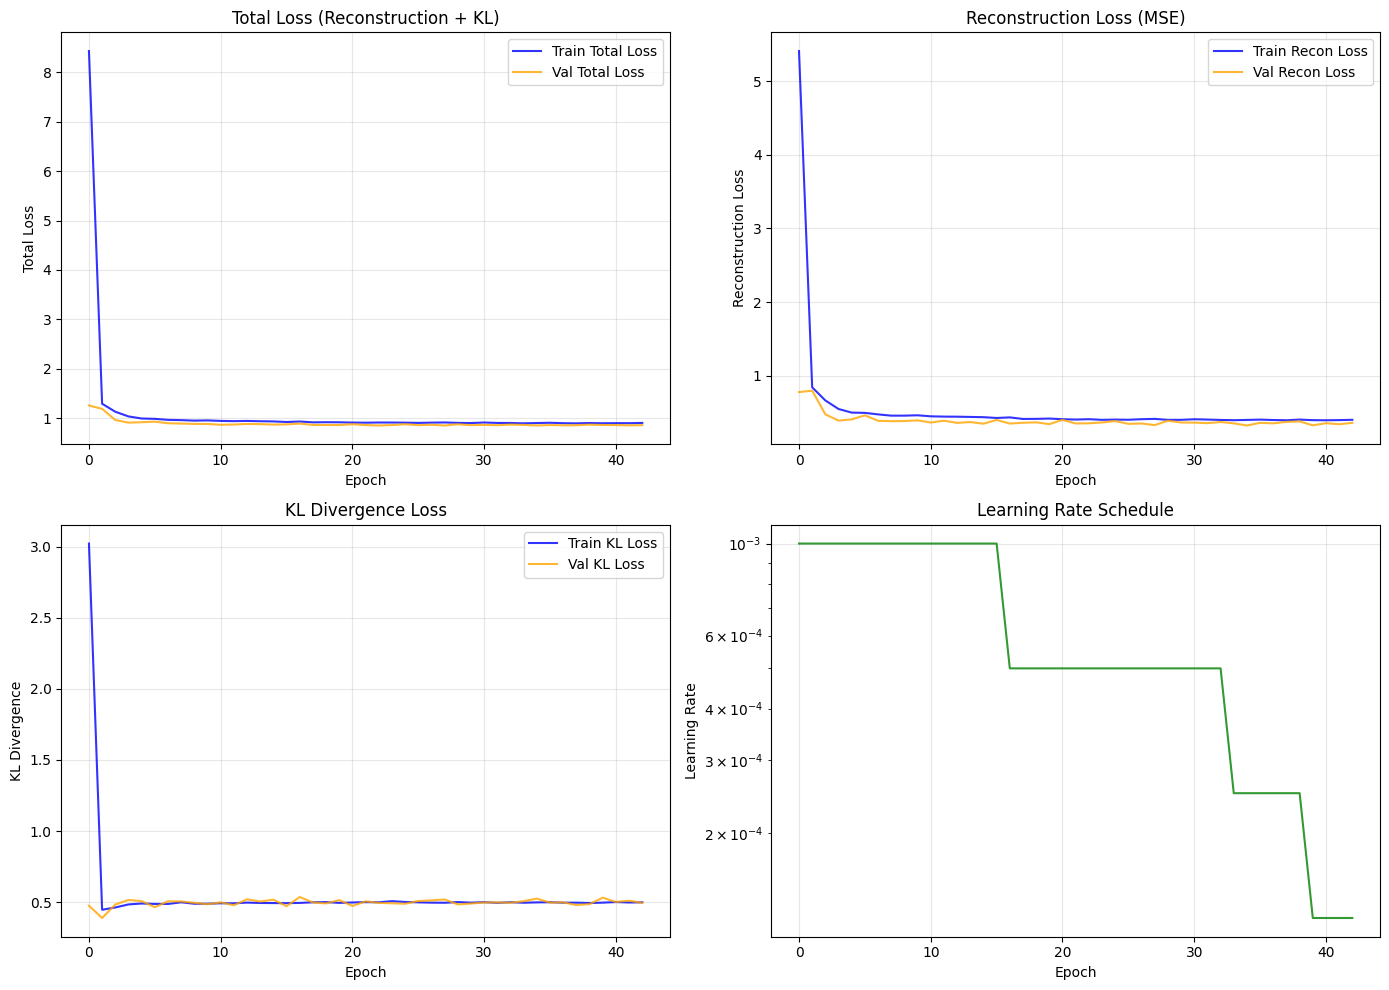

In [20]:
# Plot training history
plot_vae_training_history(history)

## Part 11: Optimal Threshold Finding

In [23]:
print("=" * 70)
print("🎯 STRATEGY 1: PERCENTILE-BASED THRESHOLD")
print("=" * 70)

# Get reconstruction errors for BENIGN validation samples only
benign_val_mask = y_val_mixed == 0
#X_val_benign = X_val_mixed[benign_val_mask]

print(f"\n📊 Using {len(X_val_benign):,} benign validation samples")

# Calculate reconstruction errors for benign samples
val_benign_loader = create_dataloader(X_val_benign, batch_size=256, shuffle=False)
benign_recon_errors = []

model.eval()
with torch.no_grad():
    for batch_x, _ in val_benign_loader:
        batch_x = batch_x.to(device)
        x_recon, z_mean, z_log_var = model(batch_x)
        recon_error = ((x_recon - batch_x) ** 2).mean(dim=1)
        benign_recon_errors.append(recon_error.cpu().numpy())

benign_recon_errors = np.concatenate(benign_recon_errors)

# Calculate thresholds at different percentiles
percentiles = [80,81,82,83,84,85,90,91,92,93,94, 95,96, 97, 99, 99.5, 99.9]
thresholds = {}

print("\n📊 Threshold Options (based on benign validation set):")
print("-" * 70)
print(f"{'Percentile':<15} {'Threshold':<15} {'Expected FPR':<20}")
print("-" * 70)

for p in percentiles:
    thresh = np.percentile(benign_recon_errors, p)
    expected_fpr = (100 - p) / 100
    thresholds[f"{p}th"] = thresh
    print(f"{p}th{'':<11} {thresh:<15.6f} {expected_fpr*100:.1f}%")

print("-" * 70)
print(f"\n💡 Interpretation:")
print(f"   - 90th percentile: Accept 10% false alarms, catch most attacks")
print(f"   - 95th percentile: Accept 5% false alarms, good balance")
print(f"   - 99th percentile: Accept 1% false alarms, conservative")
print(f"   - 99.9th percentile: Accept 0.1% false alarms, very conservative")

# Evaluate each threshold on FULL validation set (to see performance)
print("\n" + "=" * 70)
print("📈 PERFORMANCE AT EACH THRESHOLD")
print("=" * 70)

# Get reconstruction errors for ALL validation samples
val_all_loader = create_dataloader(X_val_mixed, batch_size=256, shuffle=False)
all_recon_errors = []

model.eval()
with torch.no_grad():
    for batch_x, _ in val_all_loader:
        batch_x = batch_x.to(device)
        x_recon, z_mean, z_log_var = model(batch_x)
        recon_error = ((x_recon - batch_x) ** 2).mean(dim=1)
        all_recon_errors.append(recon_error.cpu().numpy())

all_recon_errors = np.concatenate(all_recon_errors)

# Evaluate performance
from sklearn.metrics import precision_score, recall_score, f1_score

results_table = []
for name, thresh in thresholds.items():
    preds = (all_recon_errors > thresh).astype(int)
    
    precision = precision_score(y_val_mixed, preds, zero_division=0)
    recall = recall_score(y_val_mixed, preds, zero_division=0)
    f1 = f1_score(y_val_mixed, preds, zero_division=0)
    
    # Confusion matrix
    tn = np.sum((preds == 0) & (y_val_mixed == 0))
    fp = np.sum((preds == 1) & (y_val_mixed == 0))
    fn = np.sum((preds == 0) & (y_val_mixed == 1))
    tp = np.sum((preds == 1) & (y_val_mixed == 1))
    
    actual_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    
    results_table.append({
        'Threshold_Type': name,
        'Threshold': thresh,
        'Precision': precision,
        'Recall': recall,
        'F1_Score': f1,
        'Actual_FPR': actual_fpr,
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn
    })

results_df = pd.DataFrame(results_table)
print("\n" + results_df.to_string(index=False))

# Highlight recommended threshold
print("\n" + "=" * 70)
print("🎯 SELECTED THRESHOLD")
print("=" * 70)

# Use 90th percentile for higher recall (catching more attacks)
optimal_threshold = thresholds['93th']

print(f"\nUsing: 93th percentile")
print(f"   Threshold: {optimal_threshold:.6f}")
print(f"   Expected FPR: ~10%")
print(f"   Reasoning: Prioritizes catching attacks (higher recall) over minimizing false alarms")
print(f"   Trade-off: Security team investigates ~10% of benign events")

🎯 STRATEGY 1: PERCENTILE-BASED THRESHOLD

📊 Using 18,062 benign validation samples

📊 Threshold Options (based on benign validation set):
----------------------------------------------------------------------
Percentile      Threshold       Expected FPR        
----------------------------------------------------------------------
80th            0.006569        20.0%
81th            0.009209        19.0%
82th            0.014350        18.0%
83th            0.016557        17.0%
84th            0.016579        16.0%
85th            0.016591        15.0%
90th            0.016638        10.0%
91th            0.016653        9.0%
92th            0.016687        8.0%
93th            0.028339        7.0%
94th            0.041514        6.0%
95th            0.053140        5.0%
96th            0.060559        4.0%
97th            0.064779        3.0%
99th            0.134877        1.0%
99.5th            0.193474        0.5%
99.9th            0.229615        0.1%
---------------------------

## Part 12: Final Evaluation on Test Set

In [24]:
def compute_reconstruction_error(model, X, device='cuda'):
    """Compute reconstruction error for input data."""
    model.eval()
    tensor_x = torch.FloatTensor(X).to(device)
    
    with torch.no_grad():
        x_recon, z_mean, z_log_var = model(tensor_x)
        recon_error = ((x_recon - tensor_x) ** 2).mean(dim=1)
    
    return recon_error.cpu().numpy()

def detect_anomalies(reconstruction_errors, threshold):
    """Detect anomalies based on reconstruction error threshold."""
    return (reconstruction_errors > threshold).astype(int)

print("\n" + "=" * 70)
print("📊 FINAL EVALUATION ON HELD-OUT TEST SET")
print("=" * 70)

test_recon_errors = compute_reconstruction_error(model, X_test_final, device)

# Apply optimal threshold
final_predictions = detect_anomalies(test_recon_errors, optimal_threshold)

# Calculate metrics
final_precision = precision_score(y_test_final, final_predictions, zero_division=0)
final_recall = recall_score(y_test_final, final_predictions, zero_division=0)
final_f1 = f1_score(y_test_final, final_predictions, zero_division=0)

print(f"\n🎯 Final Test Results (Threshold: {optimal_threshold:.6f}):")
print(f"   Precision: {final_precision:.4f}")
print(f"   Recall:    {final_recall:.4f}")
print(f"   F1-Score:  {final_f1:.4f}")

print("\n" + "=" * 70)
print("📋 DETAILED CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_test_final, final_predictions,
                          target_names=['Benign', 'Malicious'],
                          digits=4))


📊 FINAL EVALUATION ON HELD-OUT TEST SET

🎯 Final Test Results (Threshold: 0.028339):
   Precision: 0.8924
   Recall:    1.0000
   F1-Score:  0.9431

📋 DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     1.0000    0.9321    0.9649     45154
   Malicious     0.8924    1.0000    0.9431     25418

    accuracy                         0.9566     70572
   macro avg     0.9462    0.9660    0.9540     70572
weighted avg     0.9612    0.9566    0.9570     70572



## Part 13: Visualizations

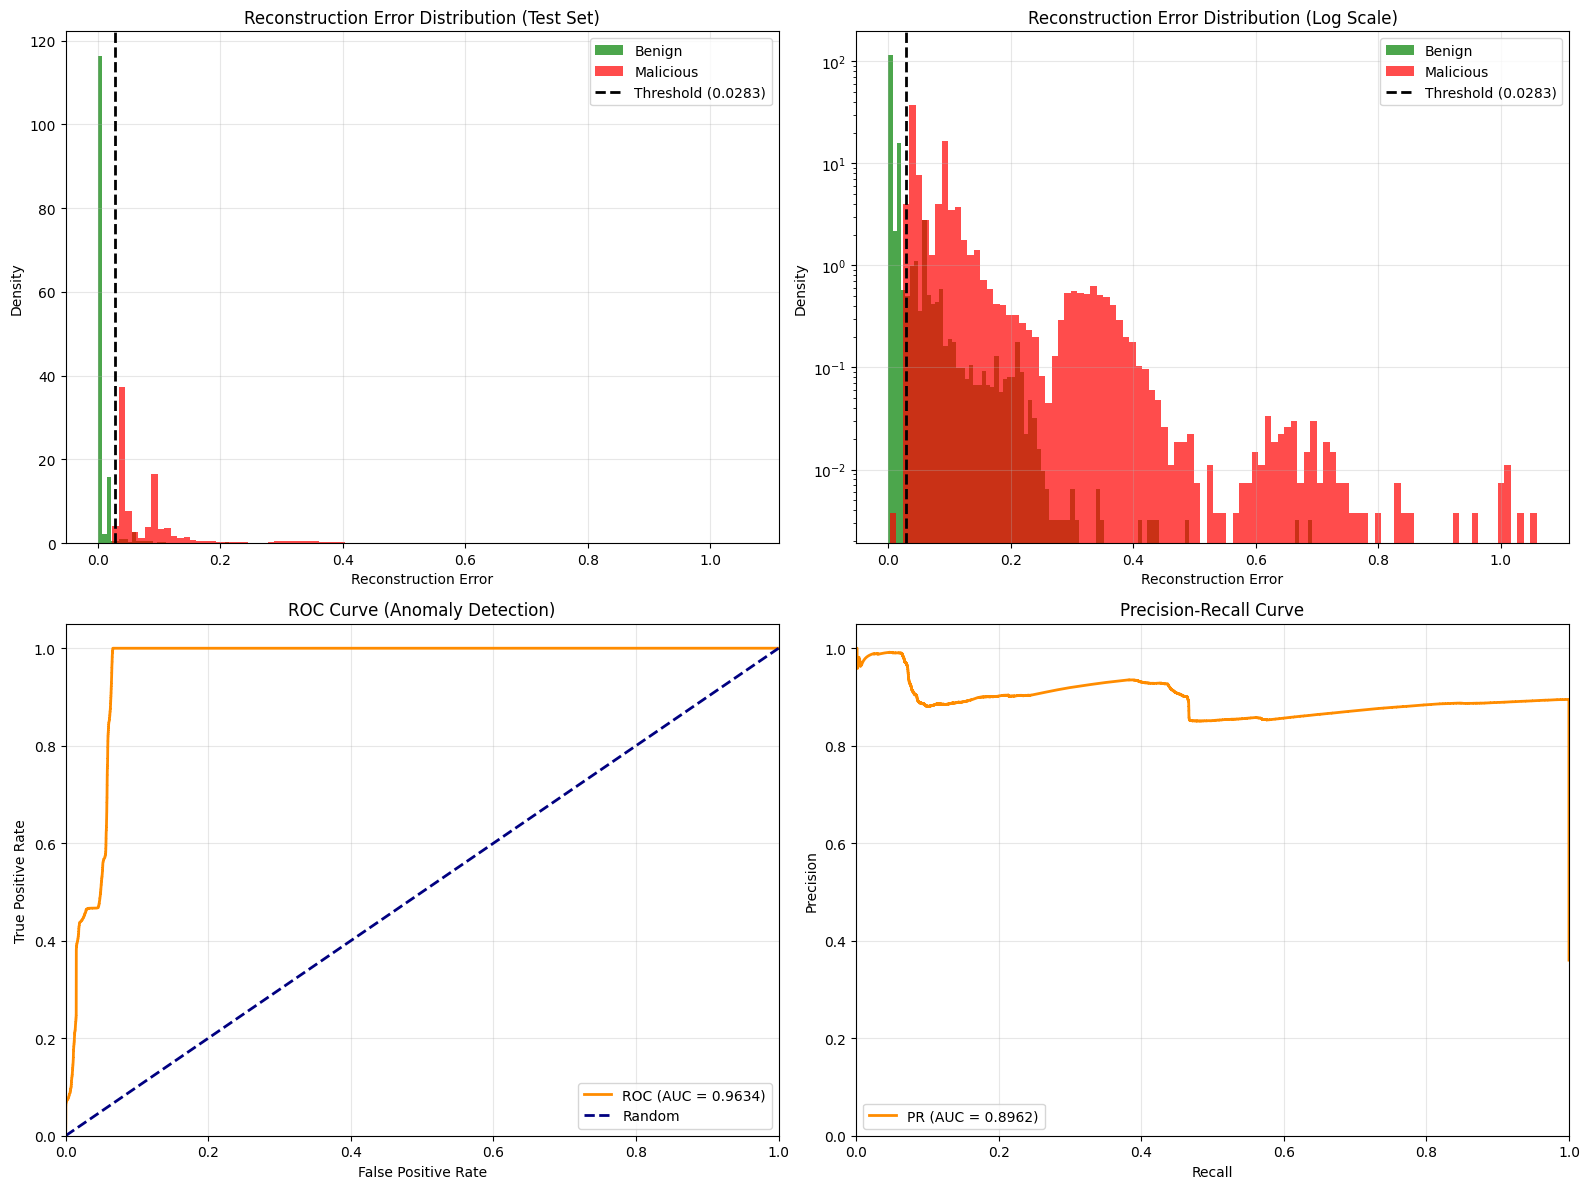

In [26]:
# Reconstruction error distributions
test_benign_errors = test_recon_errors[y_test_final == 0]
test_malicious_errors = test_recon_errors[y_test_final == 1]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Reconstruction Error Distribution
ax1 = axes[0, 0]
ax1.hist(test_benign_errors, bins=100, alpha=0.7, label='Benign', color='green', density=True)
ax1.hist(test_malicious_errors, bins=100, alpha=0.7, label='Malicious', color='red', density=True)
ax1.axvline(optimal_threshold, color='black', linestyle='--', linewidth=2,
            label=f'Threshold ({optimal_threshold:.4f})')
ax1.set_xlabel('Reconstruction Error')
ax1.set_ylabel('Density')
ax1.set_title('Reconstruction Error Distribution (Test Set)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Reconstruction Error Distribution (Log Scale)
ax2 = axes[0, 1]
ax2.hist(test_benign_errors, bins=100, alpha=0.7, label='Benign', color='green', density=True)
ax2.hist(test_malicious_errors, bins=100, alpha=0.7, label='Malicious', color='red', density=True)
ax2.axvline(optimal_threshold, color='black', linestyle='--', linewidth=2,
            label=f'Threshold ({optimal_threshold:.4f})')
ax2.set_xlabel('Reconstruction Error')
ax2.set_ylabel('Density')
ax2.set_title('Reconstruction Error Distribution (Log Scale)')
ax2.set_yscale('log')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. ROC Curve
ax3 = axes[1, 0]
fpr, tpr, _ = roc_curve(y_test_final, test_recon_errors)
roc_auc = auc(fpr, tpr)
ax3.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
ax3.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
ax3.set_xlim([0.0, 1.0])
ax3.set_ylim([0.0, 1.05])
ax3.set_xlabel('False Positive Rate')
ax3.set_ylabel('True Positive Rate')
ax3.set_title('ROC Curve (Anomaly Detection)')
ax3.legend(loc="lower right")
ax3.grid(True, alpha=0.3)

# 4. Precision-Recall Curve
ax4 = axes[1, 1]
precision_curve, recall_curve, _ = precision_recall_curve(y_test_final, test_recon_errors)
pr_auc = auc(recall_curve, precision_curve)
ax4.plot(recall_curve, precision_curve, color='darkorange', lw=2, label=f'PR (AUC = {pr_auc:.4f})')
ax4.set_xlim([0.0, 1.0])
ax4.set_ylim([0.0, 1.05])
ax4.set_xlabel('Recall')
ax4.set_ylabel('Precision')
ax4.set_title('Precision-Recall Curve')
ax4.legend(loc="lower left")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

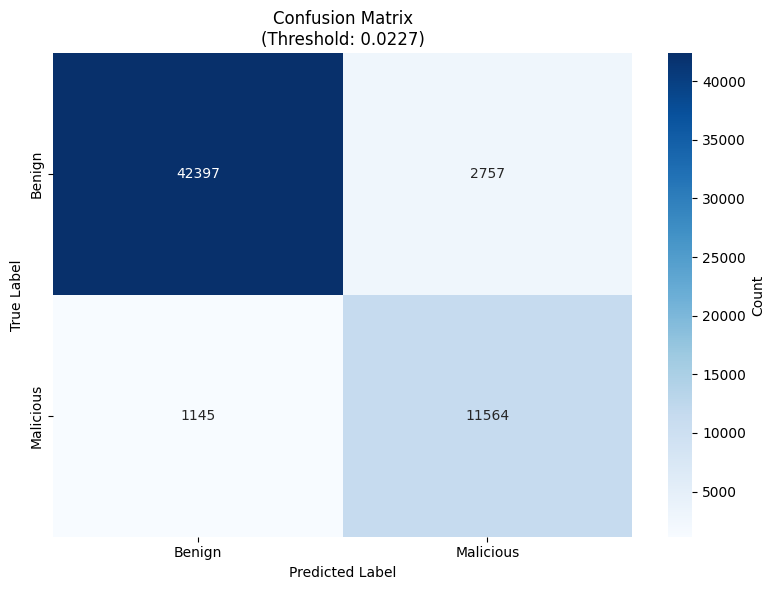

In [50]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test_final, final_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Benign', 'Malicious'],
            yticklabels=['Benign', 'Malicious'],
            cbar_kws={'label': 'Count'})
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
ax.set_title(f'Confusion Matrix\n(Threshold: {optimal_threshold:.4f})')
plt.tight_layout()
plt.show()

## Part 14: Save Model and Results

In [51]:
import pickle
import os

output_dir = 'vae_anomaly_detector_outputs'
os.makedirs(output_dir, exist_ok=True)

print("\n" + "=" * 70)
print("💾 SAVING MODEL AND RESULTS")
print("=" * 70)

# Save the trained VAE model
torch.save({
    'model_state_dict': model.state_dict(),
    'input_dim': input_dim,
    'latent_dim': latent_dim,
    'optimal_threshold': optimal_threshold,
    'training_history': history
}, os.path.join(output_dir, 'vae_anomaly_detector.pth'))

print(f"✅ Model saved to {output_dir}/vae_anomaly_detector.pth")

# Save reconstruction errors and predictions
results_df = pd.DataFrame({
    'reconstruction_error': test_recon_errors,
    'true_label': y_test_final,
    'predicted_label': final_predictions,
    'cyber_kill_chain_tactic': y_ckc_test_final
})
results_df.to_csv(os.path.join(output_dir, 'test_results.csv'), index=False)
print(f"✅ Results saved to {output_dir}/test_results.csv")

# Save feature processor
with open(os.path.join(output_dir, 'feature_processor.pkl'), 'wb') as f:
    pickle.dump(processor, f)
print(f"✅ Feature processor saved to {output_dir}/feature_processor.pkl")

# Save summary statistics
summary = {
    'optimal_threshold': optimal_threshold,
    'roc_auc': roc_auc,
    'pr_auc': pr_auc,
    'precision': final_precision,
    'recall': final_recall,
    'f1_score': final_f1,
    'benign_mean_error': test_benign_errors.mean(),
    'malicious_mean_error': test_malicious_errors.mean(),
    'separation_ratio': test_malicious_errors.mean() / test_benign_errors.mean()
}

with open(os.path.join(output_dir, 'summary_statistics.txt'), 'w') as f:
    for key, value in summary.items():
        f.write(f"{key}: {value}\n")
print(f"✅ Summary statistics saved to {output_dir}/summary_statistics.txt")

print("\n" + "=" * 70)
print("✅ ALL RESULTS SAVED!")
print("=" * 70)


💾 SAVING MODEL AND RESULTS
✅ Model saved to vae_anomaly_detector_outputs/vae_anomaly_detector.pth
✅ Results saved to vae_anomaly_detector_outputs/test_results.csv
✅ Feature processor saved to vae_anomaly_detector_outputs/feature_processor.pkl
✅ Summary statistics saved to vae_anomaly_detector_outputs/summary_statistics.txt

✅ ALL RESULTS SAVED!


## Final Summary

In [27]:
print("\n" + "=" * 70)
print("🎉 VAE ANOMALY DETECTION - COMPLETE!")
print("=" * 70)

print("\n📊 Final Results Summary:")
print(f"   Training samples (benign): {X_train_benign.shape[0]:,}")
print(f"   Test samples (mixed): {X_test_final.shape[0]:,}")
print(f"   - Benign: {np.sum(y_test_final == 0):,}")
print(f"   - Malicious: {np.sum(y_test_final == 1):,}")

print(f"\n🎯 Best Performance:")
print(f"   Optimal Threshold: {optimal_threshold:.6f}")
print(f"   ROC-AUC: {roc_auc:.4f}")
print(f"   Precision: {final_precision:.4f}")
print(f"   Recall: {final_recall:.4f}")
print(f"   F1-Score: {final_f1:.4f}")

print(f"\n📈 Reconstruction Error Separation:")
print(f"   Benign mean: {test_benign_errors.mean():.6f}")
print(f"   Malicious mean: {test_malicious_errors.mean():.6f}")
print(f"   Ratio: {test_malicious_errors.mean() / test_benign_errors.mean():.2f}x")

print("\n" + "=" * 70)


🎉 VAE ANOMALY DETECTION - COMPLETE!

📊 Final Results Summary:
   Training samples (benign): 72,246
   Test samples (mixed): 70,572
   - Benign: 45,154
   - Malicious: 25,418

🎯 Best Performance:
   Optimal Threshold: 0.028339
   ROC-AUC: 0.9634
   Precision: 0.8924
   Recall: 1.0000
   F1-Score: 0.9431

📈 Reconstruction Error Separation:
   Benign mean: 0.008127
   Malicious mean: 0.088042
   Ratio: 10.83x



## Part 7: Evaluation and Analysis

Now we'll:
1. Extract latent vectors for all data
2. Calculate reconstruction errors (anomaly scores)
3. Visualize the latent space using t-SNE
4. Analyze clusters by Cyber Kill Chain stages

In [53]:
def extract_latent_vectors(model, X, batch_size=256, device='cpu'):
    """
    Extract latent vectors for all samples.

    Returns:
        latent_vectors: numpy array of shape (n_samples, latent_dim)
        reconstruction_errors: numpy array of shape (n_samples,)
    """
    model.eval()

    # Create data loader
    tensor_x = torch.FloatTensor(X)
    dataset = TensorDataset(tensor_x)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    latent_vectors = []
    reconstruction_errors = []

    with torch.no_grad():
        for batch in loader:
            batch_x = batch[0].to(device)

            # Forward pass
            reconstructed, z_mean, z_log_var = model(batch_x)

            # Calculate per-sample reconstruction error (MSE)
            mse = ((reconstructed - batch_x) ** 2).mean(dim=1)

            latent_vectors.append(z_mean.cpu().numpy())
            reconstruction_errors.append(mse.cpu().numpy())

    latent_vectors = np.vstack(latent_vectors)
    reconstruction_errors = np.concatenate(reconstruction_errors)

    return latent_vectors, reconstruction_errors


# Extract latent vectors and reconstruction errors for ALL test data
print("🔍 Extracting latent vectors for all test data...")
X_all = X_test.astype(np.float32)
latent_vectors, reconstruction_errors = extract_latent_vectors(model, X_all, device=device)

print(f"\n✅ Extraction complete!")
print(f"   Latent vectors shape: {latent_vectors.shape}")
print(f"   Reconstruction errors shape: {reconstruction_errors.shape}")
print(f"\n📊 Reconstruction Error Statistics:")
print(f"   Mean: {reconstruction_errors.mean():.6f}")
print(f"   Std: {reconstruction_errors.std():.6f}")
print(f"   Min: {reconstruction_errors.min():.6f}")
print(f"   Max: {reconstruction_errors.max():.6f}")

🔍 Extracting latent vectors for all test data...

✅ Extraction complete!
   Latent vectors shape: (115726, 32)
   Reconstruction errors shape: (115726,)

📊 Reconstruction Error Statistics:
   Mean: 0.068259
   Std: 1.088433
   Min: 0.000014
   Max: 34.361511


RECONSTRUCTION ERROR ANALYSIS BY CLASS

📊 Reconstruction Error by Malicious Label:
             count      mean       std       min       25%       50%  \
malicious                                                              
0          90308.0  0.016887  0.443489  0.000014  0.004235  0.006245   
1          25418.0  0.250778  2.156951  0.004694  0.028764  0.034904   

                75%        max  
malicious                       
0          0.010099  31.163425  
1          0.052402  34.361511  

📊 Reconstruction Error by Cyber Kill Chain Tactic:
              count      mean       std       min       25%       50%  \
ckc_tactic                                                              
S1            643.0  0.158819  0.025658  0.133859  0.147533  0.150852   
S3          16556.0  0.337686  2.666306  0.004694  0.028325  0.031457   
S4           4291.0  0.073418  0.053112  0.016588  0.028177  0.040602   
S5           1281.0  0.086770  0.361618  0.026474  0.070205  0.071376   
S7    

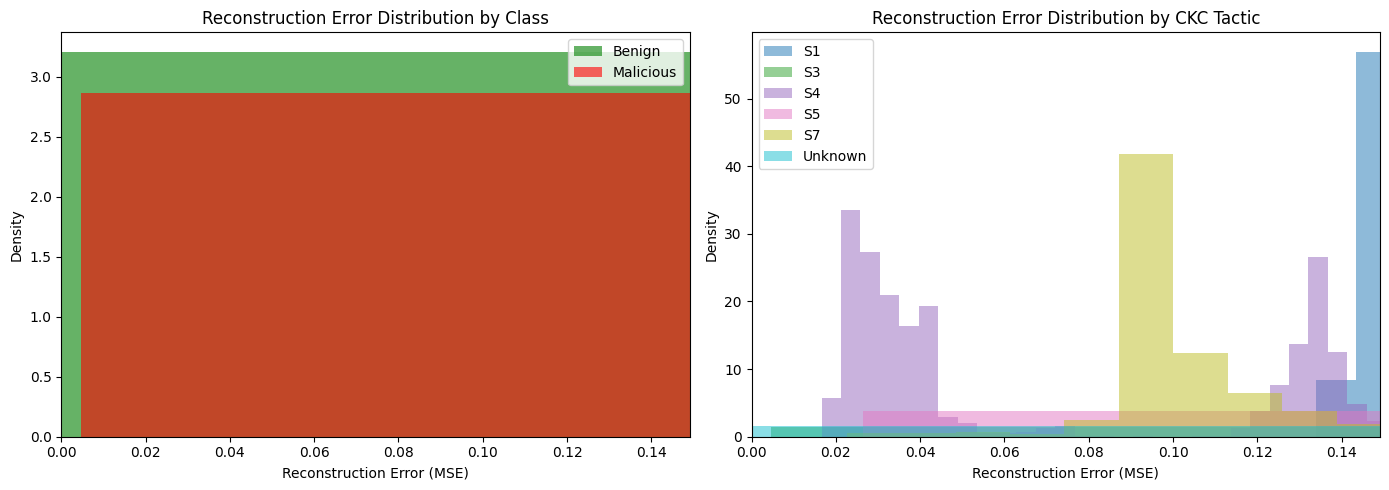

In [54]:
# Analyze reconstruction error by malicious/benign
print("=" * 60)
print("RECONSTRUCTION ERROR ANALYSIS BY CLASS")
print("=" * 60)

# Create analysis dataframe
analysis_df = pd.DataFrame({
    'reconstruction_error': reconstruction_errors,
    'malicious': y_test,
    'ckc_tactic': y_ckc_test
})

# Statistics by class
print("\n📊 Reconstruction Error by Malicious Label:")
print(analysis_df.groupby('malicious')['reconstruction_error'].describe())

print("\n📊 Reconstruction Error by Cyber Kill Chain Tactic:")
print(analysis_df.groupby('ckc_tactic')['reconstruction_error'].describe())

# Plot reconstruction error distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By malicious label
for label, color in [(0, 'green'), (1, 'red')]:
    mask = y_test == label
    axes[0].hist(reconstruction_errors[mask], bins=100, alpha=0.6,
                 label=f'{"Malicious" if label else "Benign"}', color=color, density=True)
axes[0].set_xlabel('Reconstruction Error (MSE)')
axes[0].set_ylabel('Density')
axes[0].set_title('Reconstruction Error Distribution by Class')
axes[0].legend()
axes[0].set_xlim(0, np.percentile(reconstruction_errors, 99))  # Trim outliers for visibility

# By CKC tactic
ckc_tactics = sorted(analysis_df['ckc_tactic'].unique())
colors = plt.cm.tab10(np.linspace(0, 1, len(ckc_tactics)))
for tactic, color in zip(ckc_tactics, colors):
    mask = y_ckc_test == tactic
    if mask.sum() > 0:
        axes[1].hist(reconstruction_errors[mask], bins=50, alpha=0.5,
                     label=f'{tactic}', color=color, density=True)
axes[1].set_xlabel('Reconstruction Error (MSE)')
axes[1].set_ylabel('Density')
axes[1].set_title('Reconstruction Error Distribution by CKC Tactic')
axes[1].legend()
axes[1].set_xlim(0, np.percentile(reconstruction_errors, 99))

plt.tight_layout()
plt.show()

### t-SNE Visualization of Latent Space

We'll use t-SNE to visualize the 64-dimensional latent space in 2D, colored by:
1. Malicious vs Benign
2. Cyber Kill Chain stage

In [55]:
# t-SNE visualization
# For efficiency, we'll use a sample if the dataset is large
print("🔍 Performing t-SNE dimensionality reduction...")

SAMPLE_SIZE = 5000  # Use a sample for faster t-SNE
np.random.seed(42)

if len(latent_vectors) > SAMPLE_SIZE:
    sample_indices = np.random.choice(len(latent_vectors), SAMPLE_SIZE, replace=False)
    latent_sample = latent_vectors[sample_indices]
    y_malicious_sample = y_test[sample_indices]
    y_ckc_sample = y_ckc_test[sample_indices]
    recon_error_sample = reconstruction_errors[sample_indices]
    print(f"   Using sample of {SAMPLE_SIZE:,} points for visualization")
else:
    sample_indices = np.arange(len(latent_vectors))
    latent_sample = latent_vectors
    y_malicious_sample = y_test
    y_ckc_sample = y_ckc_test
    recon_error_sample = reconstruction_errors

# Perform t-SNE
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000, learning_rate='auto', init='pca')
latent_2d = tsne.fit_transform(latent_sample)

print(f"✅ t-SNE complete! Shape: {latent_2d.shape}")

🔍 Performing t-SNE dimensionality reduction...
   Using sample of 5,000 points for visualization
✅ t-SNE complete! Shape: (5000, 2)


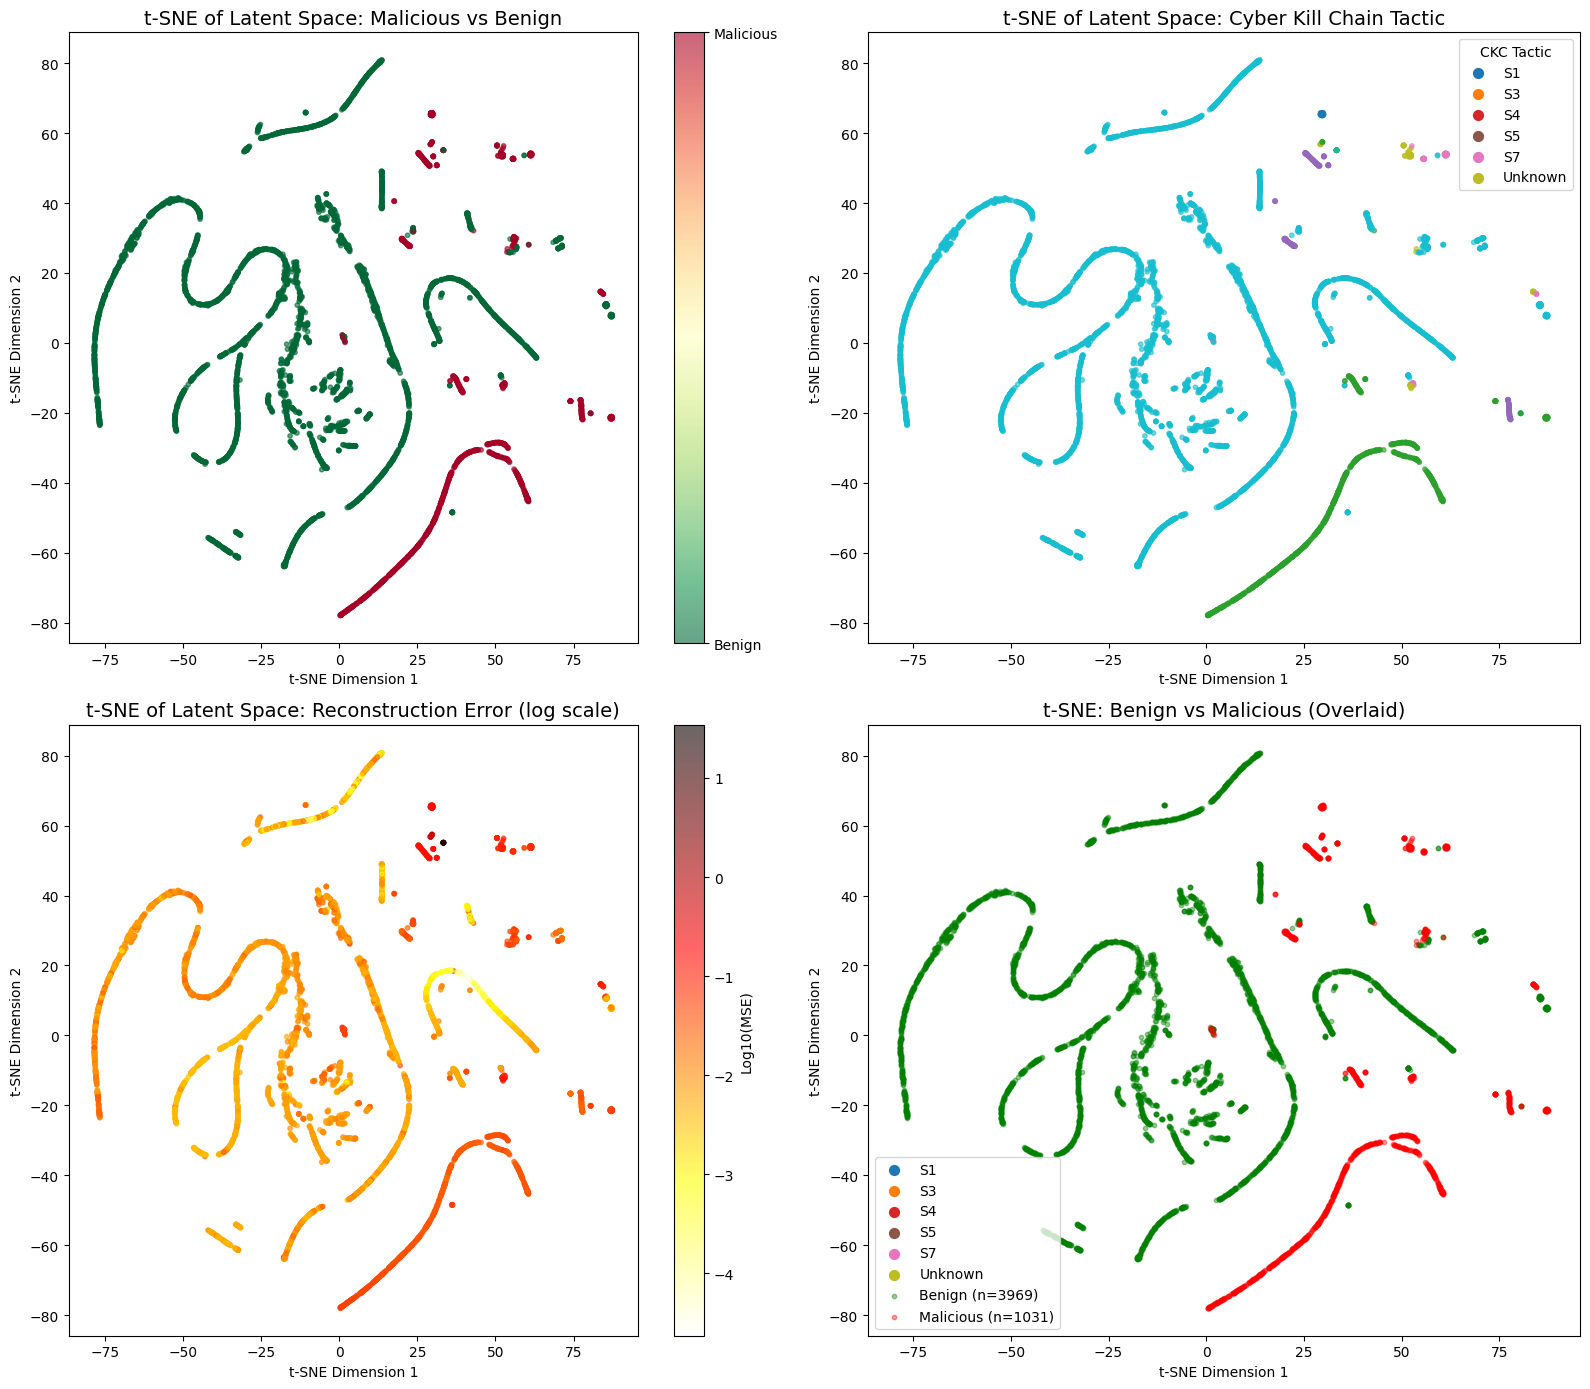


📊 Interpretation:
   - If malicious samples cluster separately → Autoencoder learned discriminative features
   - High reconstruction error regions may indicate anomalous behavior
   - Different CKC stages should ideally form distinct clusters


In [56]:
# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# 1. t-SNE colored by Malicious/Benign
ax1 = axes[0, 0]
scatter1 = ax1.scatter(latent_2d[:, 0], latent_2d[:, 1],
                       c=y_malicious_sample, cmap='RdYlGn_r',
                       alpha=0.6, s=10)
ax1.set_title('t-SNE of Latent Space: Malicious vs Benign', fontsize=14)
ax1.set_xlabel('t-SNE Dimension 1')
ax1.set_ylabel('t-SNE Dimension 2')
cbar1 = plt.colorbar(scatter1, ax=ax1)
cbar1.set_ticks([0, 1])
cbar1.set_ticklabels(['Benign', 'Malicious'])

# 2. t-SNE colored by Cyber Kill Chain Tactic
ax2 = axes[0, 1]
ckc_unique = sorted(np.unique(y_ckc_sample))
ckc_to_num = {tactic: i for i, tactic in enumerate(ckc_unique)}
ckc_numeric = np.array([ckc_to_num[t] for t in y_ckc_sample])

scatter2 = ax2.scatter(latent_2d[:, 0], latent_2d[:, 1],
                       c=ckc_numeric, cmap='tab10',
                       alpha=0.6, s=10)
ax2.set_title('t-SNE of Latent Space: Cyber Kill Chain Tactic', fontsize=14)
ax2.set_xlabel('t-SNE Dimension 1')
ax2.set_ylabel('t-SNE Dimension 2')
# Create custom legend
handles = [plt.scatter([], [], c=plt.cm.tab10(ckc_to_num[t]/len(ckc_unique)), s=50, label=t)
           for t in ckc_unique]
ax2.legend(handles=handles, title='CKC Tactic', loc='best')

# 3. t-SNE colored by Reconstruction Error
ax3 = axes[1, 0]
# Use log scale for better visibility
recon_log = np.log10(recon_error_sample + 1e-8)
scatter3 = ax3.scatter(latent_2d[:, 0], latent_2d[:, 1],
                       c=recon_log, cmap='hot_r',
                       alpha=0.6, s=10)
ax3.set_title('t-SNE of Latent Space: Reconstruction Error (log scale)', fontsize=14)
ax3.set_xlabel('t-SNE Dimension 1')
ax3.set_ylabel('t-SNE Dimension 2')
cbar3 = plt.colorbar(scatter3, ax=ax3)
cbar3.set_label('Log10(MSE)')

# 4. Separate benign and malicious plots
ax4 = axes[1, 1]
benign_mask = y_malicious_sample == 0
malicious_mask = y_malicious_sample == 1

ax4.scatter(latent_2d[benign_mask, 0], latent_2d[benign_mask, 1],
            c='green', alpha=0.4, s=10, label=f'Benign (n={benign_mask.sum()})')
ax4.scatter(latent_2d[malicious_mask, 0], latent_2d[malicious_mask, 1],
            c='red', alpha=0.4, s=10, label=f'Malicious (n={malicious_mask.sum()})')
ax4.set_title('t-SNE: Benign vs Malicious (Overlaid)', fontsize=14)
ax4.set_xlabel('t-SNE Dimension 1')
ax4.set_ylabel('t-SNE Dimension 2')
ax4.legend()

plt.tight_layout()
plt.show()

print("\n📊 Interpretation:")
print("   - If malicious samples cluster separately → Autoencoder learned discriminative features")
print("   - High reconstruction error regions may indicate anomalous behavior")
print("   - Different CKC stages should ideally form distinct clusters")

## Part 8: Anomaly Detection using Reconstruction Error

For anomaly detection, we train on **benign data only** and use reconstruction error as the anomaly score. Events with high reconstruction error are flagged as potentially malicious.

In [57]:
# Train autoencoder on BENIGN data only for anomaly detection
print("=" * 60)
print("TRAINING AUTOENCODER FOR ANOMALY DETECTION (Benign Only)")
print("=" * 60)

# Create data loaders for benign-only training
train_loader_benign = create_dataloader(X_train_benign, batch_size=BATCH_SIZE, shuffle=True)
val_loader_benign = create_dataloader(X_val_benign, batch_size=BATCH_SIZE, shuffle=False)

# Initialize a new model
model_anomaly = SIEMVAE(input_dim=input_dim, latent_dim=64, dropout_rate=0.2)
model_anomaly = model_anomaly.to(device)

# Train the model
history_anomaly = train_vae(
    model=model_anomaly,
    train_loader=train_loader_benign,
    val_loader=val_loader_benign,
    epochs=100,
    lr=1e-3,
    weight_decay=1e-5,
    patience=15,
    device=device
)

TRAINING AUTOENCODER FOR ANOMALY DETECTION (Benign Only)
TRAINING VARIATIONAL AUTOENCODER (VAE)
Epochs: 100, LR: 0.001, Weight Decay: 1e-05
Early Stopping Patience: 15
Epoch [  1/100] | Total: 24.3222/6.4995 | Recon: 17.1121/5.3908 | KL: 7.2101/1.1087 | LR: 1.00e-03
Epoch [  5/100] | Total: 5.2910/4.8003 | Recon: 3.8272/3.3917 | KL: 1.4638/1.4086 | LR: 1.00e-03
Epoch [ 10/100] | Total: 4.7436/4.4138 | Recon: 3.2367/2.9645 | KL: 1.5069/1.4494 | LR: 1.00e-03
Epoch [ 15/100] | Total: 4.6382/4.3492 | Recon: 3.1405/2.9046 | KL: 1.4976/1.4446 | LR: 1.00e-03
Epoch [ 20/100] | Total: 4.5835/4.3119 | Recon: 3.0820/2.7792 | KL: 1.5016/1.5327 | LR: 1.00e-03
Epoch [ 25/100] | Total: 4.5467/4.3110 | Recon: 3.0446/2.8002 | KL: 1.5021/1.5107 | LR: 1.00e-03
Epoch [ 30/100] | Total: 4.5175/4.3051 | Recon: 3.0245/2.8615 | KL: 1.4931/1.4436 | LR: 1.00e-03
Epoch [ 35/100] | Total: 4.4918/4.2962 | Recon: 2.9899/2.7939 | KL: 1.5019/1.5023 | LR: 1.00e-03
Epoch [ 40/100] | Total: 3.8380/4.3662 | Recon: 2.2914

In [58]:
# Evaluate anomaly detection performance
print("=" * 60)
print("ANOMALY DETECTION EVALUATION")
print("=" * 60)

# Extract reconstruction errors for ALL data using benign-trained model
_, recon_errors_anomaly = extract_latent_vectors(model_anomaly, X_all, device=device)

# Compare reconstruction errors
print("\n📊 Reconstruction Error (Benign-trained model):")
print(f"   Benign samples - Mean: {recon_errors_anomaly[y_test == 0].mean():.6f}, "
      f"Std: {recon_errors_anomaly[y_test == 0].std():.6f}")
print(f"   Malicious samples - Mean: {recon_errors_anomaly[y_test == 1].mean():.6f}, "
      f"Std: {recon_errors_anomaly[y_test == 1].std():.6f}")

# Calculate threshold for anomaly detection
# Typically use mean + k*std of benign reconstruction errors
benign_errors = recon_errors_anomaly[y_test == 0]
threshold_2std = benign_errors.mean() + 2 * benign_errors.std()
threshold_3std = benign_errors.mean() + 3 * benign_errors.std()

print(f"\n🎯 Anomaly Detection Thresholds:")
print(f"   Mean + 2σ: {threshold_2std:.6f}")
print(f"   Mean + 3σ: {threshold_3std:.6f}")

# Calculate detection metrics at different thresholds
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, accuracy_score

# Predictions at threshold
predictions_2std = (recon_errors_anomaly > threshold_2std).astype(int)
predictions_3std = (recon_errors_anomaly > threshold_3std).astype(int)

print(f"\n📈 Detection Metrics (Threshold = Mean + 2σ):")
print(f"   Accuracy:  {accuracy_score(y_test, predictions_2std):.4f}")
print(f"   Precision: {precision_score(y_test, predictions_2std):.4f}")
print(f"   Recall:    {recall_score(y_test, predictions_2std):.4f}")
print(f"   F1-Score:  {f1_score(y_test, predictions_2std):.4f}")

print(f"\n📈 Detection Metrics (Threshold = Mean + 3σ):")
print(f"   Accuracy:  {accuracy_score(y_test, predictions_3std):.4f}")
print(f"   Precision: {precision_score(y_test, predictions_3std):.4f}")
print(f"   Recall:    {recall_score(y_test, predictions_3std):.4f}")
print(f"   F1-Score:  {f1_score(y_test, predictions_3std):.4f}")

# ROC-AUC Score
roc_auc = roc_auc_score(y_test, recon_errors_anomaly)
print(f"\n🎯 ROC-AUC Score: {roc_auc:.4f}")

ANOMALY DETECTION EVALUATION

📊 Reconstruction Error (Benign-trained model):
   Benign samples - Mean: 0.015537, Std: 0.353566
   Malicious samples - Mean: 0.184004, Std: 1.504314

🎯 Anomaly Detection Thresholds:
   Mean + 2σ: 0.722669
   Mean + 3σ: 1.076235

📈 Detection Metrics (Threshold = Mean + 2σ):
   Accuracy:  0.7820
   Precision: 0.8789
   Recall:    0.0089
   F1-Score:  0.0175

📈 Detection Metrics (Threshold = Mean + 3σ):
   Accuracy:  0.7820
   Precision: 0.8784
   Recall:    0.0088
   F1-Score:  0.0175

🎯 ROC-AUC Score: 0.9483


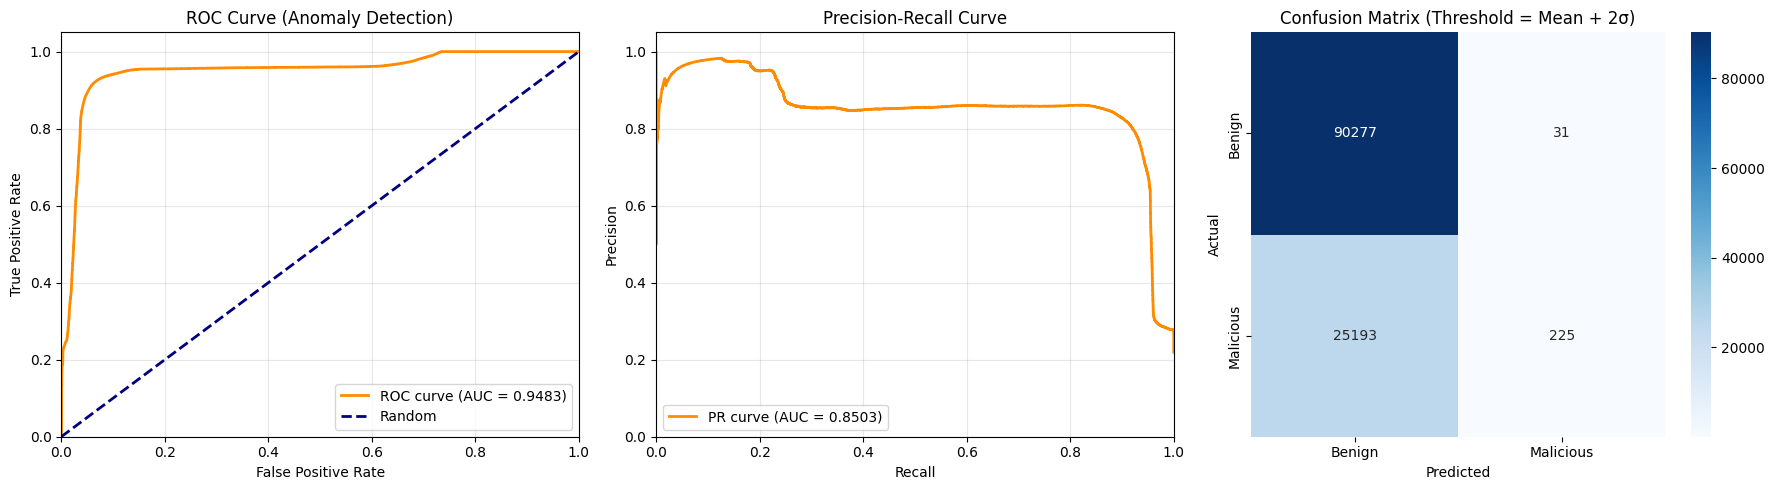

In [59]:
# Plot ROC Curve and Precision-Recall Curve
from sklearn.metrics import roc_curve, precision_recall_curve, auc

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, recon_errors_anomaly)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve (Anomaly Detection)')
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, recon_errors_anomaly)
pr_auc = auc(recall, precision)
axes[1].plot(recall, precision, color='darkorange', lw=2, label=f'PR curve (AUC = {pr_auc:.4f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend(loc="lower left")
axes[1].grid(True, alpha=0.3)

# Confusion Matrix at optimal threshold
cm = confusion_matrix(y_test, predictions_2std)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].set_title(f'Confusion Matrix (Threshold = Mean + 2σ)')

plt.tight_layout()
plt.show()

## Part 9: Save Model and Export Latent Vectors

Now we'll save:
1. The trained autoencoder model
2. The latent vectors (64-dim embeddings) for use in GNN / sequence modeling
3. The feature processor for inference on new data

In [ ]:
import pickle
import os

# Create output directory
output_dir = "vae_anomaly_detector_outputs"
os.makedirs(output_dir, exist_ok=True)

# 1. Save the PyTorch models
print("💾 Saving models...")

# Dimensionality reduction model (trained on all data)
torch.save({
    'model_state_dict': model.state_dict(),
    'input_dim': input_dim,
    'latent_dim': 64,
    'architecture': 'SIEMAutoencoder'
}, os.path.join(output_dir, 'autoencoder_dimreduction.pth'))

# Anomaly detection model (trained on benign only)
torch.save({
    'model_state_dict': model_anomaly.state_dict(),
    'input_dim': input_dim,
    'latent_dim': 64,
    'architecture': 'SIEMAutoencoder',
    'threshold_2std': threshold_2std,
    'threshold_3std': threshold_3std
}, os.path.join(output_dir, 'autoencoder_anomaly_detection.pth'))

print(f"   ✅ Models saved to {output_dir}")

# 2. Save the latent vectors as CSV and NPY
print("\n💾 Saving latent vectors...")

# Create dataframe with latent vectors + metadata
latent_df = pd.DataFrame(
    latent_vectors,
    columns=[f'latent_{i}' for i in range(latent_vectors.shape[1])]
)
latent_df['malicious'] = y_test
latent_df['cyber_kill_chain_tactic'] = y_ckc_test
latent_df['reconstruction_error'] = reconstruction_errors

# Save as CSV
latent_df.to_csv(os.path.join(output_dir, 'latent_vectors.csv'), index=False)
print(f"   ✅ Latent vectors CSV saved ({latent_df.shape[0]:,} samples, {latent_df.shape[1]} columns)")

# Save as NumPy for faster loading
np.save(os.path.join(output_dir, 'latent_vectors.npy'), latent_vectors)
np.save(os.path.join(output_dir, 'labels_malicious.npy'), y_test)
np.save(os.path.join(output_dir, 'labels_ckc.npy'), y_ckc_test)
np.save(os.path.join(output_dir, 'reconstruction_errors.npy'), reconstruction_errors)
print(f"   ✅ NumPy arrays saved")

# 3. Save the feature processor
print("\n💾 Saving feature processor...")
with open(os.path.join(output_dir, 'feature_processor.pkl'), 'wb') as f:
    pickle.dump(processor, f)
print(f"   ✅ Feature processor saved")

# 4. Save training history
print("\n💾 Saving training history...")
history_df = pd.DataFrame(history)
history_df.to_csv(os.path.join(output_dir, 'training_history.csv'), index=False)
print(f"   ✅ Training history saved")

print("\n" + "=" * 60)
print("ALL OUTPUTS SAVED!")
print("=" * 60)
print(f"\nOutput directory: {output_dir}")
print("\nFiles created:")
for f in os.listdir(output_dir):
    size = os.path.getsize(os.path.join(output_dir, f)) / 1024
    print(f"   📄 {f} ({size:.1f} KB)")